In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("/content/loan_prediction_train.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0,128,360,1,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508,128,360,1,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0,66,360,1,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358,120,360,1,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0,141,360,1,Urban,Y


In [ ]:
print("shape:", df.shape)

shape: (101, 13)


In [ ]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,101.000000,101.000000,101.000000,101.000000,101.000000
mean,4092.168317,1135.376238,116.039604,354.653465,0.920792
std,1525.950327,1638.905573,41.006566,31.861085,0.271410
min,1299.000000,0.000000,17.000000,120.000000,0.000000
25%,3036.000000,0.000000,90.000000,360.000000,1.000000
50%,3750.000000,1000.000000,115.000000,360.000000,1.000000
75%,4950.000000,1808.000000,136.000000,360.000000,1.000000
max,12841.000000,10968.000000,349.000000,360.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Loan_ID            101 non-null    object
 1   Gender             101 non-null    object
 2   Married            101 non-null    object
 3   Dependents         101 non-null    object
 4   Education          101 non-null    object
 5   Self_Employed      101 non-null    object
 6   ApplicantIncome    101 non-null    int64 
 7   CoapplicantIncome  101 non-null    int64 
 8   LoanAmount         101 non-null    int64 
 9   Loan_Amount_Term   101 non-null    int64 
 10  Credit_History     101 non-null    int64 
 11  Property_Area      101 non-null    object
 12  Loan_Status        101 non-null    object
dtypes: int64(5), object(8)
memory usage: 10.4+ KB


In [ ]:
df.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [ ]:
df.drop("Loan_ID", axis=1, inplace=True, errors="ignore")

for col in df.select_dtypes(include="object").columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

for col in df.select_dtypes(include="number").columns:
    df[col].fillna(df[col].median(), inplace=True)

le = LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col])

print("After cleaning:")
print(df.isnull().sum())

After cleaning:
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [ ]:
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training size:", X_train.shape)
print("Testing size:", X_test.shape)

Training size: (80, 11)
Testing size: (21, 11)


In [ ]:
model =  DecisionTreeClassifier(
    max_depth=5,
    criterion="gini",
    random_state=42
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nclassification Report:")
print(classification_report(y_test , y_pred,target_names=["Rejected", "Approved"]))



Accuracy: 85.71%

classification Report:
              precision    recall  f1-score   support

    Rejected       0.60      0.75      0.67         4
    Approved       0.94      0.88      0.91        17

    accuracy                           0.86        21
   macro avg       0.77      0.82      0.79        21
weighted avg       0.87      0.86      0.86        21



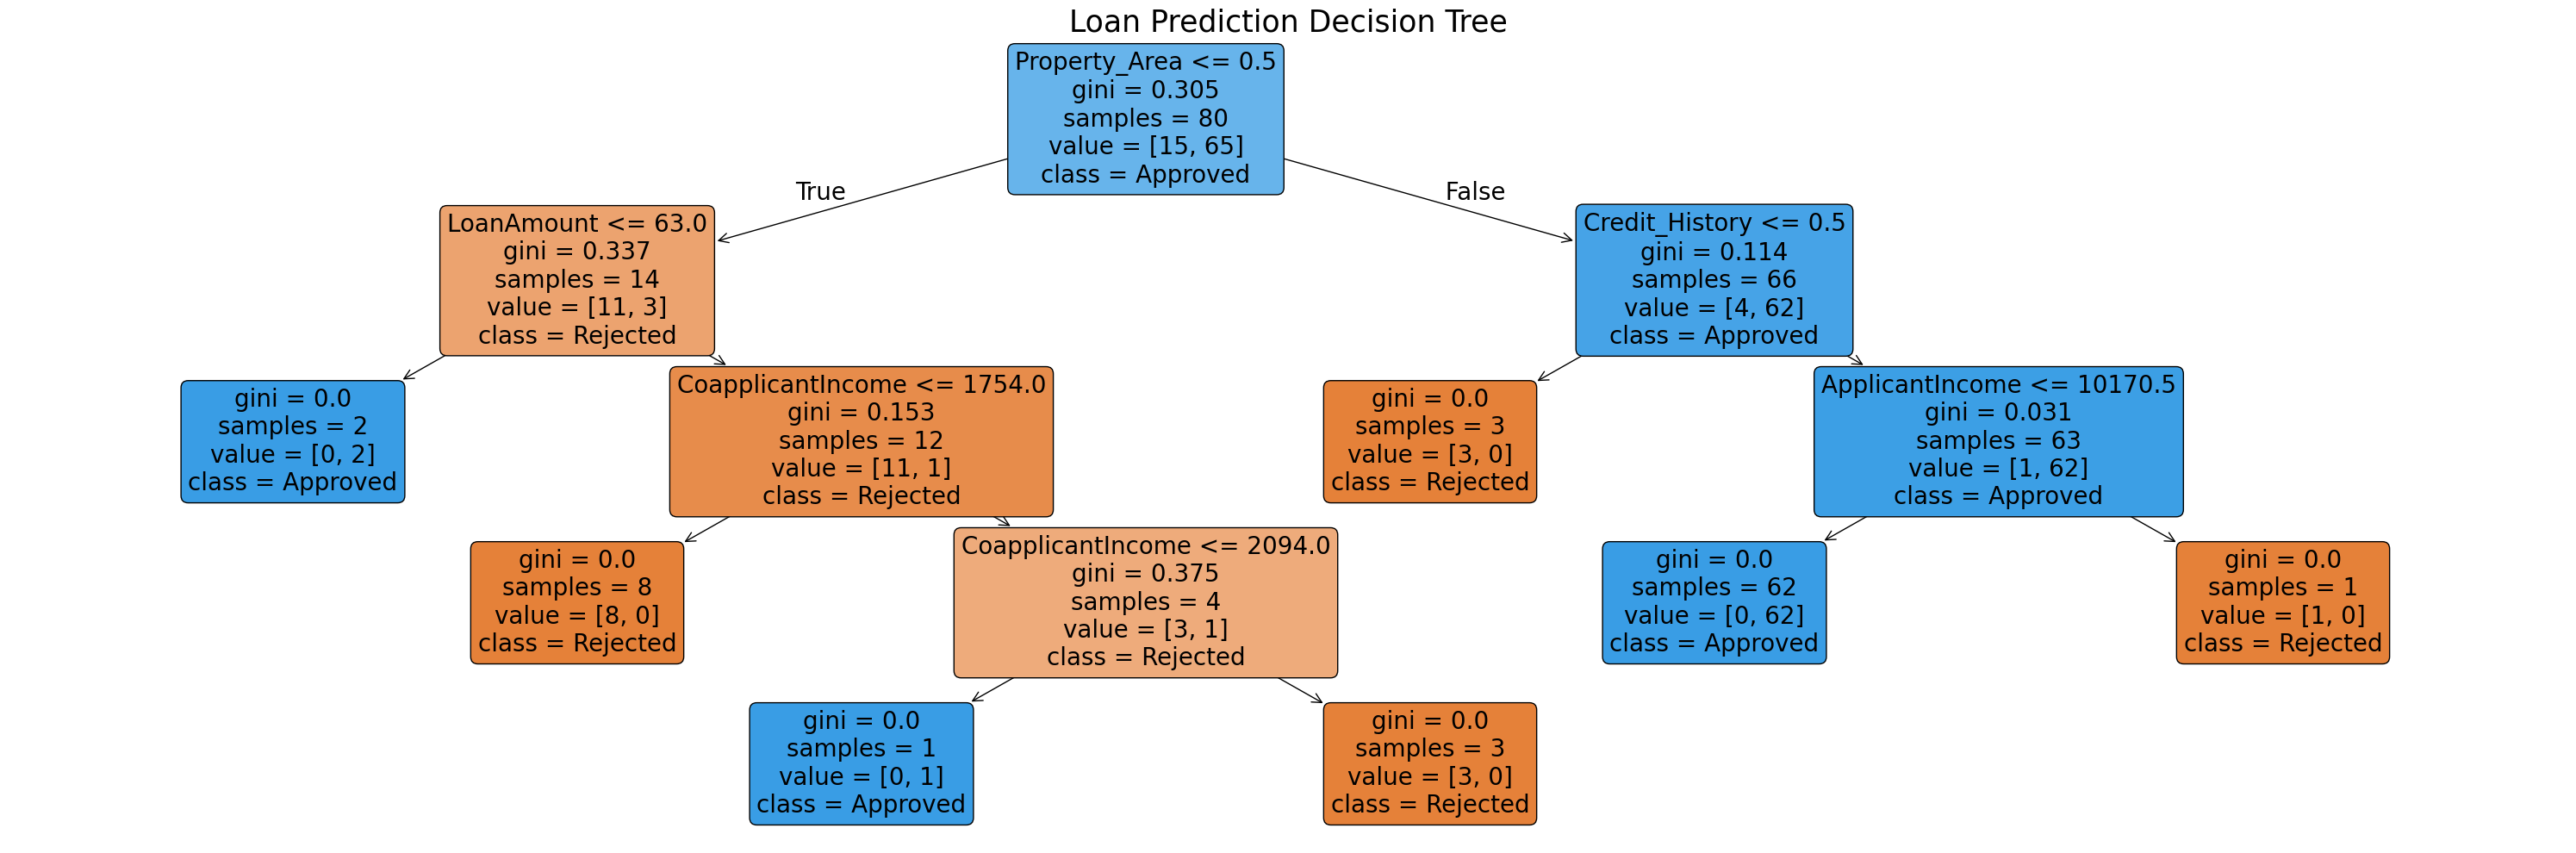

Tree saved as decision_tree.png


In [ ]:
plt.figure(figsize=(30,10))
plot_tree(model, feature_names=X.columns.tolist(), class_names=["Rejected", "Approved"],  filled=True, rounded=True, fontsize=20)
plt.title("Loan Prediction Decision Tree",fontsize=25)
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()
print("Tree saved as decision_tree.png")


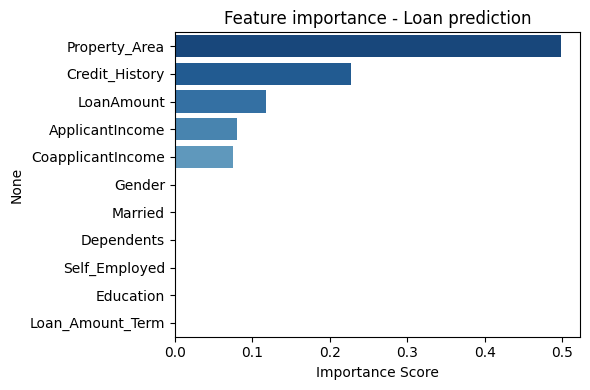


Top features
Property_Area        0.498279
Credit_History       0.227565
LoanAmount           0.118193
ApplicantIncome      0.080749
CoapplicantIncome    0.075214
dtype: float64


In [ ]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(6,4))
sns.barplot(x=importances.values, y=importances.index, palette="Blues_r")
plt.title("Feature importance - Loan prediction")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

print("\nTop features")
print(importances.head())

In [ ]:
new_applicant = pd.DataFrame({
    "Gender": [1],
    "Married": [1],
    "Dependents": [0],
    "Education": [0],
    "Self_Employed": [0],
    "ApplicantIncome": [5000],
    "CoapplicantIncome":[2000],
    "LoanAmount": [150],
    "Loan_Amount_Term": [360],
    "Credit_History": [1],
    "Property_Area": [2]

})

prediction = model.predict(new_applicant)
result = "[]Loan Approved!" if prediction[0] == 1 else "Loan Rejected"
print(result)


[]Loan Approved!


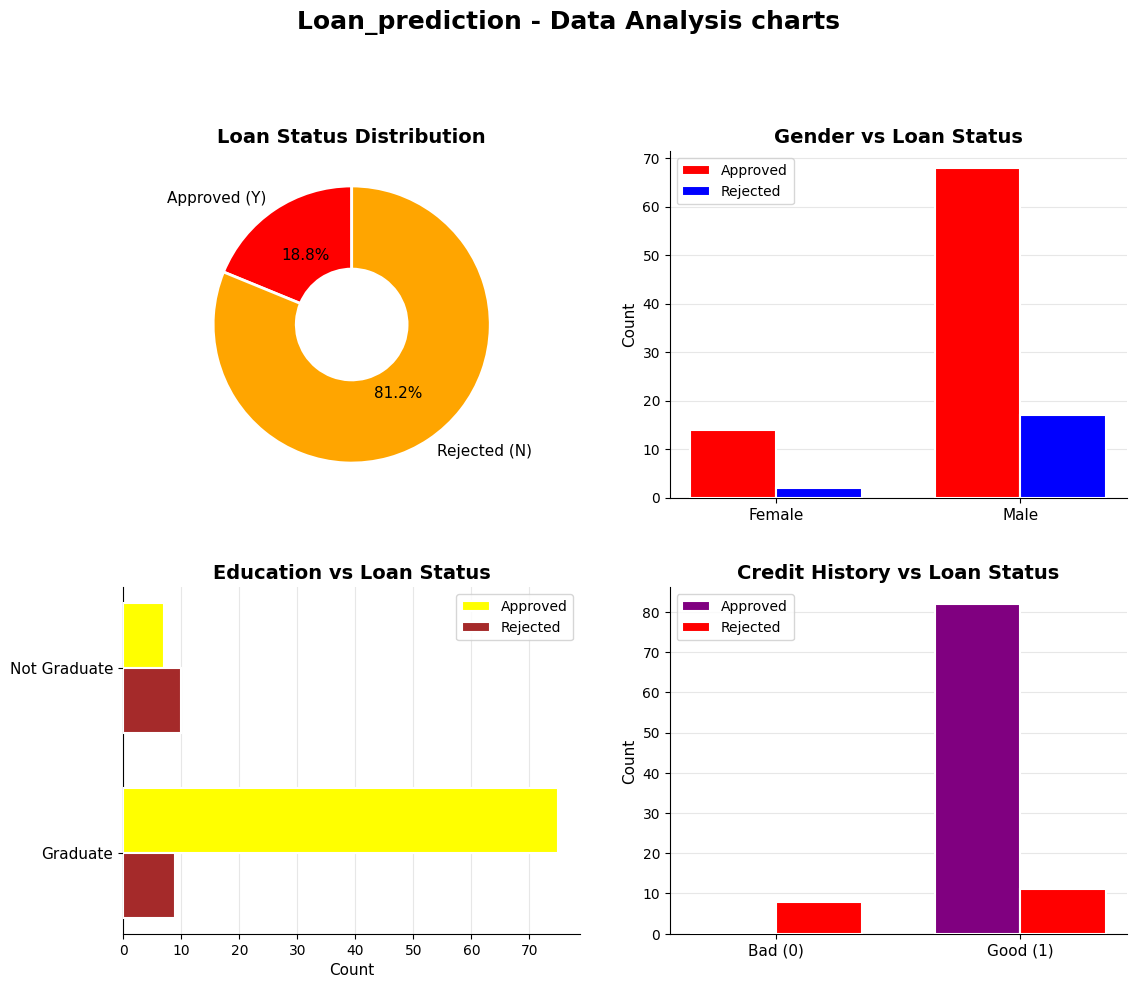

Charts saved as loan_charts.png


In [ ]:
fig, axes = plt.subplots(2,2, figsize=(12,10))
fig.suptitle("Loan_prediction - Data Analysis charts", fontsize=18, fontweight="bold", y=1.01)
fig.patch.set_facecolor("white")
colors_approved = ["red", "orange"]

# ____ chart 1: Donut Chart - Loan status ___

ax1 = axes[0,0]
loan_counts = df["Loan_Status"].value_counts()
labels = ["Approved (Y)", "Rejected (N)"]
# After LabelEncoder, 1 is 'Y' (Approved) and 0 is 'N' (Rejected)
sizes = [loan_counts.get(1, 0), loan_counts.get(0, 0)]
wedges, texts, autotexts = ax1.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    colors=colors_approved,
    startangle=90,
    wedgeprops=dict(width=0.6, edgecolor="white", linewidth=2),
    textprops={"fontsize":11}
)
ax1.set_title("Loan Status Distribution", fontsize=14, fontweight="bold")

# __ chart 2: Grouped Bar - Gender vs loan Status

ax2 = axes[0,1]
gender_status = df.groupby(["Gender", "Loan_Status"]).size().unstack(fill_value=0)
X = np.arange(len(gender_status.index))
width = 0.35
bars1 = ax2.bar(X - width/2, gender_status.get("Y", 0), width, label="Approved", color="red", edgecolor="white", linewidth=1.5, zorder=3)
bars2 = ax2.bar(X + width/2, gender_status.get("N", 0), width, label="Rejected", color="blue", edgecolor="white", linewidth=1.5, zorder=3)
ax2.set_title("Gender vs Loan Status", fontsize=14, fontweight="bold")
ax2.set_xticks(X)
ax2.set_xticklabels(gender_status.index, fontsize=11)
ax2.set_ylabel("Count", fontsize=11)
ax2.legend(fontsize=10)
ax2.set_facecolor("white")
ax2.grid(axis="y", alpha=0.3, zorder=0)
ax2.spines[["top", "right"]].set_visible(False)

# ____ chart 3: horizontal bar = education vs loan status __
ax3 = axes[1,0]
edu_status = df.groupby(["Education", "Loan_Status"]).size().unstack(fill_value=0)
y = np.arange(len(edu_status.index))
height = 0.35
bars3 = ax3.barh(y + height/2, edu_status.get("Y", 0), height, label="Approved", color="yellow", edgecolor="white", linewidth=1.5, zorder=3)
bars4 = ax3.barh(y - height/2, edu_status.get("N", 0), height, label="Rejected", color="brown", edgecolor="white", linewidth=1.5, zorder=3)
ax3.set_title("Education vs Loan Status", fontsize=14, fontweight="bold")
ax3.set_yticks(y)
ax3.set_yticklabels(edu_status.index, fontsize=11)
ax3.set_xlabel("Count", fontsize=11)
ax3.legend(fontsize=10)
ax3.set_facecolor("white")
ax3.grid(axis="x", alpha=0.3, zorder=0)
ax3.spines[["top", "right"]].set_visible(False)

#___ chart 4: credit history vs loan status
ax4 = axes[1,1]
credit_status = df.groupby(["Credit_History", "Loan_Status"]).size().unstack(fill_value=0)
credit_status.index = ["Bad (0)", "Good (1)"]
X2 = np.arange(len(credit_status.index))
bars5 = ax4.bar(X2 - width/2, credit_status.get("Y", 0), width, label="Approved", color="purple", edgecolor="white", linewidth=1.5, zorder=3)
bars6 = ax4.bar(X2 + width/2, credit_status.get("N", 0), width, label="Rejected", color="red", edgecolor="white", linewidth=1.5, zorder=3)
ax4.set_title("Credit History vs Loan Status", fontsize=14, fontweight="bold")
ax4.set_xticks(X2)
ax4.set_xticklabels(credit_status.index, fontsize=11)
ax4.set_ylabel("Count", fontsize=11)
ax4.legend(fontsize=10)
ax4.set_facecolor("white")
ax4.grid(axis="y", alpha=0.3, zorder=0)
ax4.spines[["top", "right"]].set_visible(False)

plt.tight_layout(pad=3.0)
plt.savefig("loan_charts.png", dpi=150, bbox_inches="tight", facecolor="red")
plt.show()
print("Charts saved as loan_charts.png")